# 03 – Model preparation and first model (MVP)

**Question:** can simple measurements (age, sex, BMI, waist) identify adults with elevated HbA1c (5.7% or higher, the start of the prediabetes range)?

**Data:** NHANES 2021–2023 (USA), a general-population survey. Files: demographics, body measurements, HbA1c, diabetes questionnaire.

## Participant flow
| Step | Count | Note |
|---|---|---|
| All participants (demographics file) | 11,933 | |
| Excluded: under 20 years | 4,124 | adults only |
| Adults (20+) | 7,809 | |
| Adults in the HbA1c file | 6,064 | |
| Excluded: HbA1c missing | 297 | no target value |
| **Final sample** | **5,767** | all matched to body measurements |

## Target
Elevated HbA1c = HbA1c ≥ 5.7. About 40% elevated, 60% not elevated.

## Predictors and leakage control
- Used: age, sex (`is_female`), BMI, waist (cm).
- Not used: HbA1c (it defines the target), diabetes questionnaire (too close to the target).
- Median fill and scaling are learned from the training data only (pipeline).

## Missing values in the final sample
BMI 81 (1.4%), waist 264 (4.6%), income 738 (12.8%, not used yet).

## Split
80/20, stratified, `random_state=42`. Train 4,613, test 1,154 (460 elevated, 694 not).

## Results (test set)
| Model | Accuracy | Recall | Precision | ROC-AUC |
|---|---|---|---|---|
| Dummy (always "not elevated") | 0.601 | 0.00 | n/a | 0.50 |
| Logistic regression | 0.681 | 0.55 | 0.61 | 0.75 |

The model finds about 55% of elevated cases and misses about 45%.

## Limits
- Only 4 predictors; survey weights not used (results describe this sample, not the whole US population).
- Default 0.5 threshold; one train/test split, no cross-validation yet.

## Next steps
Add race, education and income; tune the threshold; compare models with cross-validation (notebooks 04–07).

## 3.1 Load the merged NHANES dataset

In [1]:
import pandas as pd

In [2]:
df= pd.read_csv(
    '../data/processed/nhanes_merged.csv'
)

#  check the dataset

print(df.shape)

display(df.head())

(5767, 16)


,SEQN,hba1c,age_years,gender_code,race_ethnicity_code,education_code,income_poverty_ratio,exam_status_code,mec_exam_weight,survey_stratum,survey_psu,weight_kg,height_cm,bmi,waist_cm,hip_cm
0,130378.0,5.6,43.0,1.0,6.0,5.0,5.00,2.0,54374.463898,173.0,2.0,86.9,179.5,27.0,98.3,102.9
1,130379.0,5.6,66.0,1.0,3.0,5.0,5.00,2.0,34084.721548,173.0,2.0,101.8,174.2,33.5,114.7,112.4
2,130380.0,6.2,44.0,2.0,2.0,3.0,1.41,2.0,81196.277992,174.0,1.0,69.4,152.9,29.7,93.5,98.0
3,130386.0,5.1,34.0,1.0,1.0,4.0,1.33,2.0,39988.452940,179.0,1.0,90.6,173.3,30.2,106.1,110.6
4,130387.0,5.9,68.0,2.0,3.0,5.0,1.32,2.0,20776.254850,181.0,1.0,103.5,155.9,42.6,122.0,148.9


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5767 entries, 0 to 5766
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   SEQN                  5767 non-null   float64
 1   hba1c                 5767 non-null   float64
 2   age_years             5767 non-null   float64
 3   gender_code           5767 non-null   float64
 4   race_ethnicity_code   5767 non-null   float64
 5   education_code        5765 non-null   float64
 6   income_poverty_ratio  5029 non-null   float64
 7   exam_status_code      5767 non-null   float64
 8   mec_exam_weight       5767 non-null   float64
 9   survey_stratum        5767 non-null   float64
 10  survey_psu            5767 non-null   float64
 11  weight_kg             5698 non-null   float64
 12  height_cm             5710 non-null   float64
 13  bmi                   5686 non-null   float64
 14  waist_cm              5503 non-null   float64
 15  hip_cm                5453 non-n

## 3.2 Data types

In [4]:
df.dtypes

SEQN                    float64
hba1c                   float64
age_years               float64
gender_code             float64
race_ethnicity_code     float64
education_code          float64
income_poverty_ratio    float64
exam_status_code        float64
mec_exam_weight         float64
survey_stratum          float64
survey_psu              float64
weight_kg               float64
height_cm               float64
bmi                     float64
waist_cm                float64
hip_cm                  float64
dtype: object

In [5]:
df.nunique()

SEQN                    5767
hba1c                    100
age_years                 61
gender_code                2
race_ethnicity_code        6
education_code             5
income_poverty_ratio     462
exam_status_code           1
mec_exam_weight         5484
survey_stratum            15
survey_psu                 2
weight_kg                998
height_cm                507
bmi                      408
waist_cm                 804
hip_cm                   699
dtype: int64

In [6]:
df.select_dtypes(include='number')

,SEQN,hba1c,age_years,gender_code,race_ethnicity_code,education_code,income_poverty_ratio,exam_status_code,mec_exam_weight,survey_stratum,survey_psu,weight_kg,height_cm,bmi,waist_cm,hip_cm
0,130378.0,5.6,43.0,1.0,6.0,5.0,5.00,2.0,54374.463898,173.0,2.0,86.9,179.5,27.0,98.3,102.9
1,130379.0,5.6,66.0,1.0,3.0,5.0,5.00,2.0,34084.721548,173.0,2.0,101.8,174.2,33.5,114.7,112.4
2,130380.0,6.2,44.0,2.0,2.0,3.0,1.41,2.0,81196.277992,174.0,1.0,69.4,152.9,29.7,93.5,98.0
3,130386.0,5.1,34.0,1.0,1.0,4.0,1.33,2.0,39988.452940,179.0,1.0,90.6,173.3,30.2,106.1,110.6
4,130387.0,5.9,68.0,2.0,3.0,5.0,1.32,2.0,20776.254850,181.0,1.0,103.5,155.9,42.6,122.0,148.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5762,142303.0,8.1,69.0,2.0,7.0,3.0,0.98,2.0,47087.576098,181.0,1.0,70.8,159.2,27.9,111.0,104.5
5763,142305.0,6.0,76.0,2.0,1.0,1.0,2.25,2.0,43483.407534,180.0,2.0,60.4,151.4,26.4,89.0,96.4
5764,142307.0,6.2,49.0,2.0,4.0,5.0,NaN,2.0,64962.328962,181.0,1.0,NaN,143.8,NaN,NaN,NaN
5765,142309.0,5.2,40.0,1.0,2.0,4.0,3.11,2.0,46249.361849,176.0,1.0,81.9,179.1,25.5,96.0,103.3


In [7]:
df['exam_status_code'].nunique()        # 1 → only one distinct value
df['exam_status_code'].value_counts()   # 2.0 → 5767

exam_status_code
2.0    5767
Name: count, dtype: int64

In [8]:
(df['age_years'] % 1==0).all() # True → no decimals hidden

cols=['SEQN', 'age_years', 'survey_stratum', 'survey_psu']

df[cols]=df[cols].astype(int)


In [9]:
df.dtypes

SEQN                      int64
hba1c                   float64
age_years                 int64
gender_code             float64
race_ethnicity_code     float64
education_code          float64
income_poverty_ratio    float64
exam_status_code        float64
mec_exam_weight         float64
survey_stratum            int64
survey_psu                int64
weight_kg               float64
height_cm               float64
bmi                     float64
waist_cm                float64
hip_cm                  float64
dtype: object

## 3.3 Recode sex and set ethnicity as a category

`is_female`: 0 = male, 1 = female. `race_ethnicity_code`: 6 groups, one-hot encoded later.

In [10]:
print(type(df))
print(df.shape)
print(df['gender_code'].value_counts())
print(df['race_ethnicity_code'].dtype)

<class 'pandas.DataFrame'>
(5767, 16)
gender_code
2.0    3181
1.0    2586
Name: count, dtype: int64
float64


In [11]:
df['gender_code'] = df['gender_code'].map({1: 0, 2: 1})
print(df['gender_code'].value_counts())

gender_code
1    3181
0    2586
Name: count, dtype: int64


In [12]:
df['race_ethnicity_code']=df['race_ethnicity_code'].astype('category')

In [13]:
print(df['race_ethnicity_code'].dtype)
print(df['race_ethnicity_code'].cat.categories)

category
Index([1.0, 2.0, 3.0, 4.0, 6.0, 7.0], dtype='float64')


In [14]:
# rename gender code

df=df.rename(columns={'gender_code': 'is_female'})


In [15]:
df['is_female'].value_counts()

is_female
1    3181
0    2586
Name: count, dtype: int64

In [16]:
print(df.columns.tolist())

['SEQN', 'hba1c', 'age_years', 'is_female', 'race_ethnicity_code', 'education_code', 'income_poverty_ratio', 'exam_status_code', 'mec_exam_weight', 'survey_stratum', 'survey_psu', 'weight_kg', 'height_cm', 'bmi', 'waist_cm', 'hip_cm']


In [17]:
print(type(df), df.shape)
print(df.columns.tolist())
print(df['is_female'].value_counts())

<class 'pandas.DataFrame'> (5767, 16)
['SEQN', 'hba1c', 'age_years', 'is_female', 'race_ethnicity_code', 'education_code', 'income_poverty_ratio', 'exam_status_code', 'mec_exam_weight', 'survey_stratum', 'survey_psu', 'weight_kg', 'height_cm', 'bmi', 'waist_cm', 'hip_cm']
is_female
1    3181
0    2586
Name: count, dtype: int64


## 3.4 Define the target y

Elevated HbA1c (≥ 5.7) = 1, otherwise 0.

In [18]:
#  creating y

threshold= 5.7

y=(df['hba1c'] >= threshold).astype(int)

y.name='elevated_hba1c'

print(y.value_counts())

elevated_hba1c
0    3468
1    2299
Name: count, dtype: int64


## 3.5 The predictors X

In [19]:
feature_col= ['age_years', 'is_female', 'bmi', 'waist_cm']

X=df[feature_col]. copy()

print(X.shape, y.shape)
print('hba1c' in X.columns)

(5767, 4) (5767,)
False


In [20]:
X.isna().sum()

age_years      0
is_female      0
bmi           81
waist_cm     264
dtype: int64

In [21]:
X.describe()

,age_years,is_female,bmi,waist_cm
count,5767.000000,5767.000000,5686.000000,5503.000000
mean,54.001907,0.551587,29.819698,101.095675
std,17.060526,0.497375,7.280716,16.757057
min,20.000000,0.000000,11.100000,60.000000
25%,39.000000,0.000000,24.700000,89.000000
50%,57.000000,1.000000,28.500000,99.600000
75%,68.000000,1.000000,33.500000,111.400000
max,80.000000,1.000000,74.800000,187.000000


In [22]:
X.groupby(y).mean()

,age_years,is_female,bmi,waist_cm
elevated_hba1c,,,,
0,49.240773,0.565167,28.493333,97.256081
1,61.183993,0.531100,31.821536,106.943971


## 3.6 Correlation of HbA1c with the four predictors, and between the predictors

In [23]:
cols=['hba1c', 'age_years', 'is_female', 'bmi', 'waist_cm']
df[cols].corr()

,hba1c,age_years,is_female,bmi,waist_cm
hba1c,1.000000,0.241840,-0.037359,0.193749,0.245283
age_years,0.241840,1.000000,-0.020624,-0.005126,0.148171
is_female,-0.037359,-0.020624,1.000000,0.062358,-0.141263
bmi,0.193749,-0.005126,0.062358,1.000000,0.896371
waist_cm,0.245283,0.148171,-0.141263,0.896371,1.000000


## 3.7 Distribution of HbA1c and the predictors

**Why:** see the shape of the target (skew, peak, extreme values) and where the 5.7 cut-off falls.
**Finding:** right-skewed, peak around 5.5, long tail up to about 17. The cut-off lies inside the crowded part.

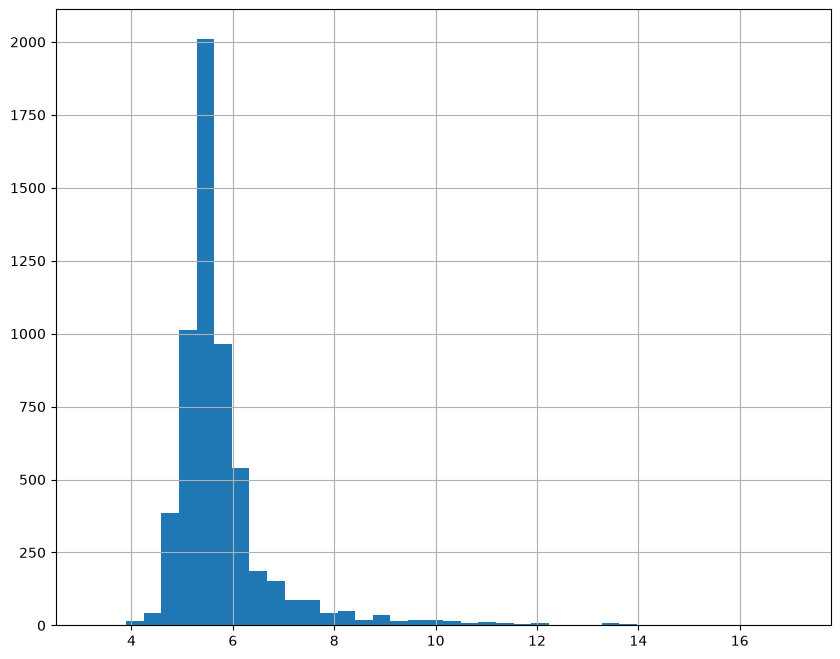

In [24]:
df['hba1c'].hist(bins=40, figsize=(10, 8));

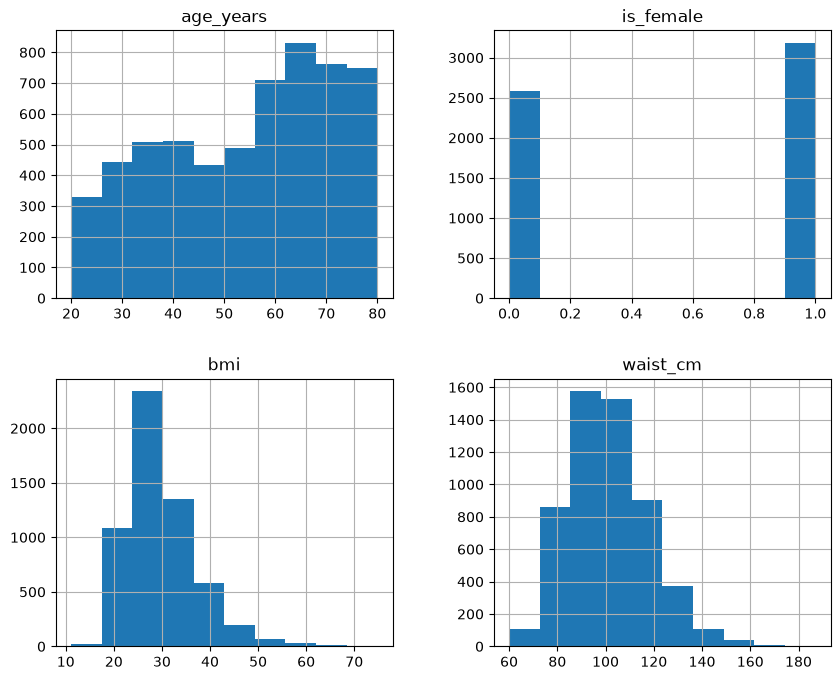

In [25]:
X.hist(figsize=(10, 8));

## 3.8 Train/test split

**Why:** test the model on people it has never seen, and split before imputing or scaling so nothing from the test set leaks into training.

In [26]:
# import the split function from scikit-learn
from sklearn.model_selection import train_test_split

# split X and y: 80% train, 20% test, same class balance, reproducible
X_train, X_test, y_train, y_test=(train_test_split(X, y, test_size=0.2, random_state=42, stratify=y))

# check the shapes of the four parts
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

# check the share of y = 1 in train and in test
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(4613, 4) (1154, 4)
(4613,) (1154,)
elevated_hba1c
0    0.601344
1    0.398656
Name: proportion, dtype: float64
elevated_hba1c
0    0.601386
1    0.398614
Name: proportion, dtype: float64


## 3.9 Baseline: always predict the most common class

**Why:** a floor that any real model must beat. It also shows why accuracy alone can mislead when classes are unbalanced.

In [27]:
# import the dummy model

from sklearn.dummy import DummyClassifier

# create a model that always predicts the most frequent class

dummy=DummyClassifier(strategy='most_frequent')

# train it on the training data

dummy.fit(X_train, y_train)

#  measure accuracy on the test data
accuracy= dummy.score(X_test, y_test)

print('Dummy accuracy:', accuracy)

Dummy accuracy: 0.6013864818024264


## 3.10 Model 1: logistic regression pipeline

**Why:** a first real model that is simple and explainable. The pipeline (median imputation → scaling → logistic regression) learns from the training data only, so nothing leaks from the test set.
**Result:** test accuracy 0.681 vs 0.601 for the dummy baseline (+8 percentage points).
**Interpretation:** age, sex, BMI and waist carry real signal for elevated HbA1c (≥ 5.7), but the model is modest, which is expected with four predictors.

In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Test accuracy:', accuracy_score(y_test, y_pred))

Test accuracy: 0.6811091854419411


## 3.11 Evaluation: confusion matrix, recall, precision and ROC-AUC

**Why:** accuracy hides which cases the model misses. For a screening question like "elevated HbA1c", finding the true cases matters.

In [29]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score, roc_auc_score

# predicted probability of being elevated (class 1)
y_proba = model.predict_proba(X_test)[:, 1]

print('Confusion matrix:\n', confusion_matrix(y_test, y_pred))
print('Recall   :', recall_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('ROC-AUC  :', roc_auc_score(y_test, y_proba))

Confusion matrix:
 [[534 160]
 [208 252]]
Recall   : 0.5478260869565217
Precision: 0.6116504854368932
ROC-AUC  : 0.7484055882721463


**Conclusion:** the model beats the baseline (accuracy 0.681 vs 0.601, ROC-AUC 0.75 vs 0.50), so age, sex, BMI and waist carry real signal for elevated HbA1c.
**Limitation:** it still misses about 45% of truly elevated people (recall 0.55). As a screening tool it would need improvement.
**Next steps:** lower the decision threshold to raise recall, add race, education and income, compare tree-based models, and use cross-validation.

## Results (test set, 1,154 people: 460 elevated, 694 not elevated)

| Measure | Dummy model | Logistic regression |
|---|---|---|
| Accuracy | 0.601 | 0.681 |
| Recall (elevated people found) | 0.00 | 0.55 |
| Precision (flagged who are truly elevated) | not defined (flags nobody) | 0.61 |
| ROC-AUC | 0.50 | 0.75 |
| Correctly predicted not elevated | 694 | 534 |
| False alarms (not elevated, flagged) | 0 | 160 |
| Missed (elevated, not flagged) | 460 | 208 |
| Correctly predicted elevated | 0 | 252 |

**Reading it:** the model beats the dummy by about 8 percentage points of accuracy (0.601 to 0.681). It finds 252 of 460 elevated people (55%) and misses 208 (45%).

## 3.12 Save the cleaned dataset (used by notebooks 04–07)

In [30]:
out_path= '../data/processed/nhanes_clean.csv'
df.to_csv(out_path, index=False)

In [31]:
check = pd.read_csv(out_path)
print(check.shape)   # should be (5767, 16)

(5767, 16)
